In [1]:
import numpy as np
import pandas as pd

In [2]:
df = pd.read_csv('/content/amazon_reviews.csv')
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (999, 10)


,Unnamed: 0,asin,helpful,overall,reviewText,reviewTime,reviewerID,reviewerName,summary,unixReviewTime
0,0,0528881469,"[0, 0]",5.0,We got this GPS for my husband who is an (OTR)...,"06 2, 2013",AO94DHGC771SJ,amazdnu,Gotta have GPS!,1.370131e+09
1,1,0528881469,"[12, 15]",1.0,"I'm a professional OTR truck driver, and I bou...","11 25, 2010",AMO214LNFCEI4,Amazon Customer,Very Disappointed,1.290643e+09
2,2,0528881469,"[43, 45]",3.0,"Well, what can I say. I've had this unit in m...","09 9, 2010",A3N7T0DY83Y4IG,C. A. Freeman,1st impression,1.283990e+09
3,3,0528881469,"[9, 10]",2.0,"Not going to write a long review, even thought...","11 24, 2010",A1H8PY3QHMQQA0,"Dave M. Shaw ""mack dave""","Great grafics, POOR GPS",1.290557e+09
4,4,0528881469,"[0, 0]",1.0,I've had mine for a year and here's what we go...,"09 29, 2011",A24EV6RXELQZ63,Wayne Smith,"Major issues, only excuses for support",1.317254e+09


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 999 entries, 0 to 998
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unnamed: 0      999 non-null    int64  
 1   asin            999 non-null    object 
 2   helpful         999 non-null    object 
 3   overall         999 non-null    float64
 4   reviewText      997 non-null    object 
 5   reviewTime      999 non-null    object 
 6   reviewerID      999 non-null    object 
 7   reviewerName    994 non-null    object 
 8   summary         999 non-null    object 
 9   unixReviewTime  999 non-null    float64
dtypes: float64(2), int64(1), object(7)
memory usage: 78.2+ KB


In [4]:
print(df.isnull().sum())

Unnamed: 0        0
asin              0
helpful           0
overall           0
reviewText        2
reviewTime        0
reviewerID        0
reviewerName      5
summary           0
unixReviewTime    0
dtype: int64


In [5]:
df = df.drop_duplicates()

In [7]:
df = df.dropna()

In [8]:
df.isna().sum()

,0
Unnamed: 0,0
asin,0
helpful,0
overall,0
reviewText,0
reviewTime,0
reviewerID,0
reviewerName,0
summary,0
unixReviewTime,0


In [11]:
def convert_sentiment(rating):
    if rating <= 2:
        return 0
    elif rating == 3:
        return 1
    else:
        return 2
df["sentiment"] = df["overall"].apply(convert_sentiment)

/tmp/ipykernel_1279/2151641992.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["sentiment"] = df["overall"].apply(convert_sentiment)


In [12]:
sentiment_mapping = {0: "Negative",1: "Neutral",2: "Positive"}
df["sentiment_name"] = df["sentiment"].map(sentiment_mapping)
print(df[["overall", "sentiment", "sentiment_name"]].head(10))

   overall  sentiment sentiment_name
0      5.0          2       Positive
1      1.0          0       Negative
2      3.0          1        Neutral
3      2.0          0       Negative
4      1.0          0       Negative
5      5.0          2       Positive
6      2.0          0       Negative
7      5.0          2       Positive
8      4.0          2       Positive
9      5.0          2       Positive


/tmp/ipykernel_1279/1769036447.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["sentiment_name"] = df["sentiment"].map(sentiment_mapping)


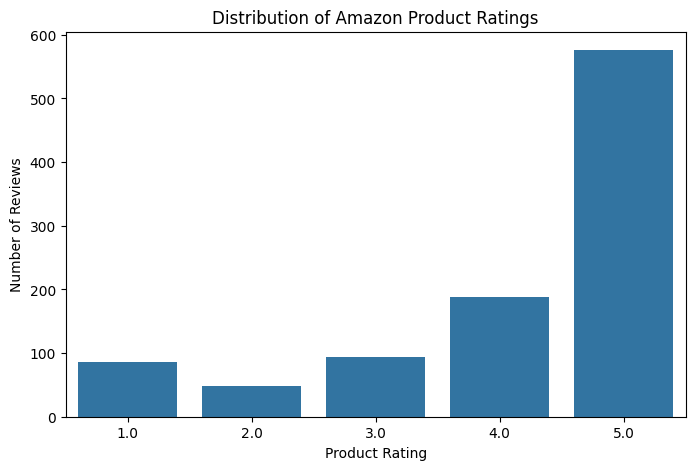

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8, 5))
sns.countplot(data=df,x="overall")

plt.title("Distribution of Amazon Product Ratings")
plt.xlabel("Product Rating")
plt.ylabel("Number of Reviews")

plt.show()

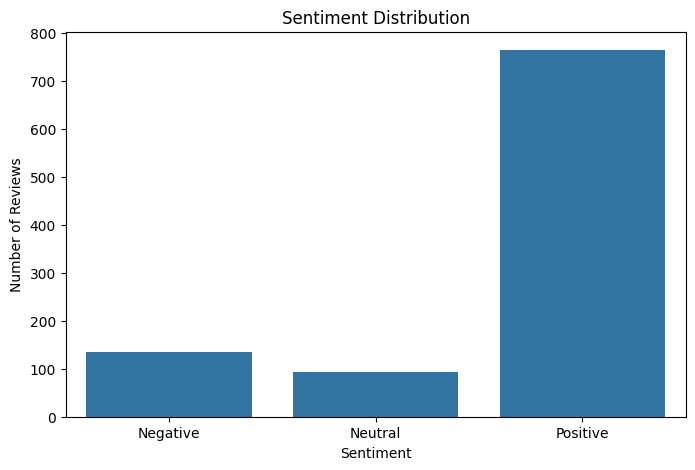

In [14]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df,x="sentiment_name",order=["Negative", "Neutral", "Positive"])

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

In [16]:
from sklearn.model_selection import train_test_split
MAX_SAMPLES = 50000
if len(df) > MAX_SAMPLES:
    df = df.sample(n=MAX_SAMPLES,random_state=42,stratify=df["sentiment"])
X = df["reviewText"].astype(str)
y = df["sentiment"].astype(int)
X_train, X_temp, y_train, y_temp = train_test_split(X,y,test_size=0.30,random_state=42,stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp,y_temp,test_size=0.50,random_state=42,stratify=y_temp)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

Training samples: 694
Validation samples: 149
Testing samples: 149


In [18]:
import re
from collections import Counter
def clean_text(text):
    text = text.lower()
    text = re.sub(r"<.*?>", " ", text)
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"[^a-zA-Z0-9\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text
train_texts = X_train.apply(clean_text).tolist()
val_texts = X_val.apply(clean_text).tolist()
test_texts = X_test.apply(clean_text).tolist()

In [19]:
MAX_VOCAB = 30000
PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"
word_counts = Counter()
for text in train_texts:
    word_counts.update(text.split())
vocab = {PAD_TOKEN: 0,UNK_TOKEN: 1}
for word, count in word_counts.most_common(MAX_VOCAB - 2):
    vocab[word] = len(vocab)
print("Vocabulary Size:", len(vocab))

Vocabulary Size: 6765


In [20]:
MAX_LEN = 128
def encode_text(text):
    tokens = text.split()
    ids = [vocab.get(word, vocab[UNK_TOKEN])for word in tokens[:MAX_LEN]]
    return ids if ids else [vocab[UNK_TOKEN]]

In [22]:
from torch.utils.data import Dataset
class ReviewDataset(Dataset):
    def __init__(self, texts, labels):
        self.texts = [encode_text(text)for text in texts]
        self.labels = labels.tolist()
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, index):
        return (torch.tensor(self.texts[index], dtype=torch.long),torch.tensor(self.labels[index], dtype=torch.long))

In [23]:
def collate_fn(batch):
    sequences, labels = zip(*batch)
    lengths = torch.tensor([len(seq) for seq in sequences],dtype=torch.long)
    padded = nn.utils.rnn.pad_sequence(sequences,batch_first=True,padding_value=vocab[PAD_TOKEN])
    labels = torch.stack(labels)
    return padded, lengths, labels

In [25]:
from torch.utils.data import DataLoader
BATCH_SIZE = 64
train_dataset = ReviewDataset(train_texts,y_train)
val_dataset = ReviewDataset(val_texts,y_val)
test_dataset = ReviewDataset(test_texts,y_test)
train_loader = DataLoader(train_dataset,batch_size=BATCH_SIZE,shuffle=True,collate_fn=collate_fn)
val_loader = DataLoader(val_dataset,batch_size=BATCH_SIZE,shuffle=False,collate_fn=collate_fn)
test_loader = DataLoader(test_dataset,batch_size=BATCH_SIZE,shuffle=False,collate_fn=collate_fn)

In [27]:
import torch.nn as nn
class LSTMClassifier(nn.Module):
    def __init__(self,vocab_size,embedding_dim=128,hidden_dim=128,num_classes=3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size,embedding_dim,padding_idx=0)
        self.lstm = nn.LSTM(input_size=embedding_dim,hidden_size=hidden_dim,batch_first=True)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(hidden_dim,num_classes)
    def forward(self, x, lengths):
        embedded = self.embedding(x)
        packed = nn.utils.rnn.pack_padded_sequence(embedded,lengths.cpu(),batch_first=True,enforce_sorted=False)
        _, (hidden, _) = self.lstm(packed)
        output = hidden[-1]
        output = self.dropout(output)
        return self.fc(output)

In [29]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
lstm_model = LSTMClassifier(vocab_size=len(vocab)).to(device)
print(lstm_model)

LSTMClassifier(
  (embedding): Embedding(6765, 128, padding_idx=0)
  (lstm): LSTM(128, 128, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=3, bias=True)
)


In [30]:
class_counts = np.bincount(y_train,minlength=3)
class_weights = len(y_train) / (3 * class_counts)
class_weights = torch.tensor(class_weights,dtype=torch.float32).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(lstm_model.parameters(),lr=0.001)

In [31]:
from tqdm.auto import tqdm
def train_lstm_epoch(model, loader):
    model.train()
    total_loss = 0
    for sequences, lengths, labels in tqdm(loader):
        sequences = sequences.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        outputs = model(sequences,lengths)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(loader)

In [32]:
def evaluate_lstm(model, loader):
    model.eval()
    predictions = []
    actual = []
    with torch.no_grad():
        for sequences, lengths, labels in loader:
            sequences = sequences.to(device)
            outputs = model(sequences,lengths)
            predicted = torch.argmax(outputs,dim=1)
            predictions.extend(predicted.cpu().numpy())
            actual.extend(labels.numpy())
    return np.array(actual), np.array(predictions)

In [35]:
import time
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
LSTM_EPOCHS = 5

lstm_history = []

start_time = time.time()

for epoch in range(LSTM_EPOCHS):

    loss = train_lstm_epoch(
        lstm_model,
        train_loader
    )

    val_actual, val_predictions = evaluate_lstm(
        lstm_model,
        val_loader
    )

    val_accuracy = accuracy_score(
        val_actual,
        val_predictions
    )

    lstm_history.append({
        "epoch": epoch + 1,
        "loss": loss,
        "val_accuracy": val_accuracy
    })

    print(
        f"Epoch {epoch+1}/{LSTM_EPOCHS} | "
        f"Loss: {loss:.4f} | "
        f"Validation Accuracy: {val_accuracy:.4f}"
    )

lstm_training_time = time.time() - start_time

print(
    "LSTM Training Time:",
    round(lstm_training_time, 2),
    "seconds"
)

  0%|          | 0/11 [00:00<?, ?it/s]

Epoch 1/5 | Loss: 1.0517 | Validation Accuracy: 0.2953


  0%|          | 0/11 [00:00<?, ?it/s]

Epoch 2/5 | Loss: 0.9979 | Validation Accuracy: 0.3356


  0%|          | 0/11 [00:00<?, ?it/s]

Epoch 3/5 | Loss: 0.9252 | Validation Accuracy: 0.3826


  0%|          | 0/11 [00:00<?, ?it/s]

Epoch 4/5 | Loss: 0.8364 | Validation Accuracy: 0.5503


  0%|          | 0/11 [00:00<?, ?it/s]

Epoch 5/5 | Loss: 0.6873 | Validation Accuracy: 0.4832
LSTM Training Time: 33.09 seconds


In [36]:
import os
os.makedirs("models", exist_ok=True)

torch.save(
    {
        "model_state_dict": lstm_model.state_dict(),
        "vocab": vocab,
        "max_len": MAX_LEN
    },
    "models/lstm_model.pth"
)

In [38]:
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)
# Load pretrained BERT tokenizer
MODEL_NAME = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

print("BERT Tokenizer Loaded!")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

BERT Tokenizer Loaded!


In [39]:
# Tokenize the review dataset
BERT_MAX_LEN = 128

class BERTDataset(Dataset):

    def __init__(self, texts, labels):

        self.encodings = tokenizer(
            texts,
            truncation=True,
            padding="max_length",
            max_length=BERT_MAX_LEN,
            return_tensors="pt"
        )

        self.labels = torch.tensor(
            labels.tolist(),
            dtype=torch.long
        )

    def __len__(self):

        return len(self.labels)

    def __getitem__(self, index):

        item = {
            key: value[index]
            for key, value in self.encodings.items()
        }

        item["labels"] = self.labels[index]

        return item

In [40]:
# Create BERT datasets
bert_train_dataset = BERTDataset(
    X_train.tolist(),
    y_train
)

bert_val_dataset = BERTDataset(
    X_val.tolist(),
    y_val
)

bert_test_dataset = BERTDataset(
    X_test.tolist(),
    y_test
)

In [41]:
# Create DataLoaders
BERT_BATCH_SIZE = 16

bert_train_loader = DataLoader(
    bert_train_dataset,
    batch_size=BERT_BATCH_SIZE,
    shuffle=True
)

bert_val_loader = DataLoader(
    bert_val_dataset,
    batch_size=BERT_BATCH_SIZE
)

bert_test_loader = DataLoader(
    bert_test_dataset,
    batch_size=BERT_BATCH_SIZE
)

In [42]:
# Load pretrained BERT model
bert_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3
)

bert_model = bert_model.to(device)

print("BERT Model Loaded Successfully!")

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT Model Loaded Successfully!


In [43]:
# Define optimizer and loss
bert_class_weights = torch.tensor(
    class_weights.cpu().numpy(),
    dtype=torch.float32
).to(device)

bert_criterion = nn.CrossEntropyLoss(
    weight=bert_class_weights
)

bert_optimizer = torch.optim.AdamW(
    bert_model.parameters(),
    lr=2e-5
)

In [44]:
# Train BERT
def train_bert_epoch(model, loader):

    model.train()

    total_loss = 0

    for batch in tqdm(loader):

        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        bert_optimizer.zero_grad()

        outputs = model(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"]
        )

        loss = bert_criterion(
            outputs.logits,
            batch["labels"]
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            1.0
        )

        bert_optimizer.step()

        total_loss += loss.item()

    return total_loss / len(loader)

In [45]:
# Evaluation function
def evaluate_bert(model, loader):

    model.eval()

    predictions = []

    actual = []

    with torch.no_grad():

        for batch in loader:

            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }

            outputs = model(
                input_ids=batch["input_ids"],
                attention_mask=batch["attention_mask"]
            )

            predicted = torch.argmax(
                outputs.logits,
                dim=1
            )

            predictions.extend(
                predicted.cpu().numpy()
            )

            actual.extend(
                batch["labels"].cpu().numpy()
            )

    return np.array(actual), np.array(predictions)

In [ ]:
# Training
BERT_EPOCHS = 2

bert_history = []

start_time = time.time()

for epoch in range(BERT_EPOCHS):

    loss = train_bert_epoch(
        bert_model,
        bert_train_loader
    )

    val_actual, val_predictions = evaluate_bert(
        bert_model,
        bert_val_loader
    )

    val_accuracy = accuracy_score(
        val_actual,
        val_predictions
    )

    bert_history.append({
        "epoch": epoch + 1,
        "loss": loss,
        "val_accuracy": val_accuracy
    })

    print(
        f"Epoch {epoch+1}/{BERT_EPOCHS} | "
        f"Loss: {loss:.4f} | "
        f"Validation Accuracy: {val_accuracy:.4f}"
    )

bert_training_time = time.time() - start_time

print(
    "BERT Training Time:",
    round(bert_training_time, 2),
    "seconds"
)

  0%|          | 0/44 [00:00<?, ?it/s]

In [ ]:
# Save the fine-tuned BERT model
bert_model.save_pretrained(
    "models/bert_model"
)

tokenizer.save_pretrained(
    "models/bert_model"
)

In [ ]:
# Evaluate LSTM
lstm_actual, lstm_predictions = evaluate_lstm(
    lstm_model,
    test_loader
)

print("LSTM Classification Report")

print(
    classification_report(
        lstm_actual,
        lstm_predictions,
        labels=[0, 1, 2],
        target_names=[
            "Negative",
            "Neutral",
            "Positive"
        ],
        zero_division=0
    )
)

In [ ]:
# Evaluate BERT
bert_actual, bert_predictions = evaluate_bert(
    bert_model,
    bert_test_loader
)

print("BERT Classification Report")

print(
    classification_report(
        bert_actual,
        bert_predictions,
        labels=[0, 1, 2],
        target_names=[
            "Negative",
            "Neutral",
            "Positive"
        ],
        zero_division=0
    )
)

In [ ]:
# Calculate evaluation metrics
def calculate_metrics(actual, predicted):

    return {
        "Accuracy": accuracy_score(
            actual,
            predicted
        ),

        "Precision": precision_score(
            actual,
            predicted,
            average="macro",
            zero_division=0
        ),

        "Recall": recall_score(
            actual,
            predicted,
            average="macro",
            zero_division=0
        ),

        "F1 Score": f1_score(
            actual,
            predicted,
            average="macro",
            zero_division=0
        )
    }


lstm_metrics = calculate_metrics(
    lstm_actual,
    lstm_predictions
)

bert_metrics = calculate_metrics(
    bert_actual,
    bert_predictions
)

comparison = pd.DataFrame(
    [lstm_metrics, bert_metrics],
    index=["LSTM", "BERT"]
)

print(comparison)

In [ ]:
# LSTM confusion matrix
cm_lstm = confusion_matrix(
    lstm_actual,
    lstm_predictions,
    labels=[0, 1, 2]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_lstm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Negative",
        "Neutral",
        "Positive"
    ],
    yticklabels=[
        "Negative",
        "Neutral",
        "Positive"
    ]
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.title("LSTM Confusion Matrix")

plt.savefig(
    "results/confusion_matrix_lstm.png",
    bbox_inches="tight"
)

plt.show()

In [ ]:
# BERT confusion matrix
cm_bert = confusion_matrix(
    bert_actual,
    bert_predictions,
    labels=[0, 1, 2]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_bert,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=[
        "Negative",
        "Neutral",
        "Positive"
    ],
    yticklabels=[
        "Negative",
        "Neutral",
        "Positive"
    ]
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.title("BERT Confusion Matrix")

plt.savefig(
    r"C:\Users\Lucky Kashyap\Desktop\MLE\amazon-review-sentiment-analysis\results\confusion_matrix_bert.png",
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Compare model accuracy
plt.figure(figsize=(8, 5))

accuracy_values = [
    lstm_metrics["Accuracy"],
    bert_metrics["Accuracy"]
]

plt.bar(
    ["LSTM", "BERT"],
    accuracy_values
)

plt.ylabel("Accuracy")

plt.title("LSTM vs BERT Accuracy Comparison")

plt.ylim(0, 1)

plt.savefig(
    r"C:\Users\Lucky Kashyap\Desktop\MLE\amazon-review-sentiment-analysis\results\model_accuracy_comparison.png",
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Compare all evaluation metrics
comparison.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Performance Comparison: LSTM vs BERT")

plt.ylabel("Score")

plt.ylim(0, 1)

plt.xticks(rotation=0)

plt.legend(loc="lower right")

plt.tight_layout()

plt.savefig(
    "results/model_comparison.png",
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Compare training time
training_times = pd.DataFrame({
    "Model": ["LSTM", "BERT"],
    "Training Time (seconds)": [
        lstm_training_time,
        bert_training_time
    ]
})

print(training_times)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=training_times,
    x="Model",
    y="Training Time (seconds)"
)

plt.title("Training Time Comparison")

plt.show()

In [ ]:
# Final comparison table
final_comparison = comparison.copy()

final_comparison["Training Time (seconds)"] = [
    lstm_training_time,
    bert_training_time
]

print("\nFINAL MODEL COMPARISON\n")

print(
    final_comparison.round(4)
)

In [ ]:
# BERT prediction function
def predict_sentiment_bert(review):

    bert_model.eval()

    inputs = tokenizer(
        review,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=128
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():

        outputs = bert_model(**inputs)

        probabilities = torch.softmax(
            outputs.logits,
            dim=1
        )

        prediction = torch.argmax(
            probabilities,
            dim=1
        ).item()

    labels = {
        0: "Negative",
        1: "Neutral",
        2: "Positive"
    }

    return {
        "sentiment": labels[prediction],
        "confidence": round(
            probabilities[0][prediction].item() * 100,
            2
        )
    }

In [ ]:
# Test the model
sample_reviews = [
    "This product is amazing. I absolutely love it!",

    "The product is okay, nothing special.",

    "Very poor quality. I regret buying this product."
]

for review in sample_reviews:

    result = predict_sentiment_bert(review)

    print("\nReview:", review)

    print("Predicted Sentiment:", result["sentiment"])

    print("Confidence:", result["confidence"], "%")